# 04 — Decision Tree

**Algorithm:** CART Decision Tree  
**Features:** TF-IDF (50K unigrams + bigrams)  
Decision Trees partition the feature space by recursively selecting the most informative split. They are inherently interpretable but prone to overfitting.

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
from utils import (setup_paths, evaluate_and_print, plot_confusion_matrix,
                   plot_roc_curve, plot_pr_curve, plot_learning_curve)
from sklearn.metrics import accuracy_score
BASE_DIR, FIGURES_DIR = setup_paths()

In [2]:
from preprocess import load_all_datasets, get_train_test_split
df = load_all_datasets()
X_train, X_test, y_train, y_test = get_train_test_split(df)
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1,2), sublinear_tf=True, min_df=2, max_df=0.95)
X_tr = tfidf.fit_transform(X_train)
X_te = tfidf.transform(X_test)
print(f'Train: {len(X_train):,}  |  Test: {len(X_test):,}  |  Features: {X_tr.shape[1]:,}')


  LOADING ALL DATASETS
  [1/5] Loading ISOT Dataset...
      Loaded 44,898 records  (Fake=23,481  Real=21,417)
  [2/5] Loading FakeNewsNet Dataset...
      Loaded 23,196 records  (Fake=5,755  Real=17,441)
  [3/5] Loading LIAR Dataset...
      Loaded 12,791 records  (Fake=5,657  Real=7,134)
  [4/5] Loading MultiFC Dataset...
      Loaded 31,921 records  (Fake=13,980  Real=17,941)
  [5/5] Loading BuzzFeed Dataset...
      Loaded 2,282 records  (Fake=613  Real=1,669)

  Combined total   : 115,088 records
  Fake (0)         : 49,486
  Real (1)         : 65,602

  Cleaning text...
  After clean+dedup: 104,521 records

  Source distribution:
source
ISOT           38826
MultiFC        31919
FakeNewsNet    21046
LIAR           12726
BuzzFeed           4
Train: 83,616  |  Test: 20,905  |  Features: 50,000


## Model Training

In [3]:
from sklearn.tree import DecisionTreeClassifier
MODEL_NAME = 'Decision Tree'
model = DecisionTreeClassifier(max_depth=50, random_state=42)
t0 = time.time()
model.fit(X_tr, y_train)
train_time = time.time() - t0
print(f'Training completed in {train_time:.2f}s')
print(f'Tree depth     : {model.get_depth()}')
print(f'Total leaves   : {model.get_n_leaves():,}')
print(f'Features used  : {(model.feature_importances_ > 0).sum():,}')

Training completed in 289.88s
Tree depth     : 50
Total leaves   : 3,355
Features used  : 2,040


In [4]:
metrics, y_pred, y_prob = evaluate_and_print(model, X_te, y_test, MODEL_NAME, train_time)


  Decision Tree — Evaluation Results
  Accuracy          : 0.8172
  Precision         : 0.8176
  Recall            : 0.8172
  F1 Score          : 0.8144
  AUC-ROC           : 0.8178
  Train Time (s)    : 289.88s

              precision    recall  f1-score   support

    Fake (0)       0.82      0.70      0.76      8532
    Real (1)       0.81      0.89      0.85     12373

    accuracy                           0.82     20905
   macro avg       0.82      0.80      0.81     20905
weighted avg       0.82      0.82      0.81     20905



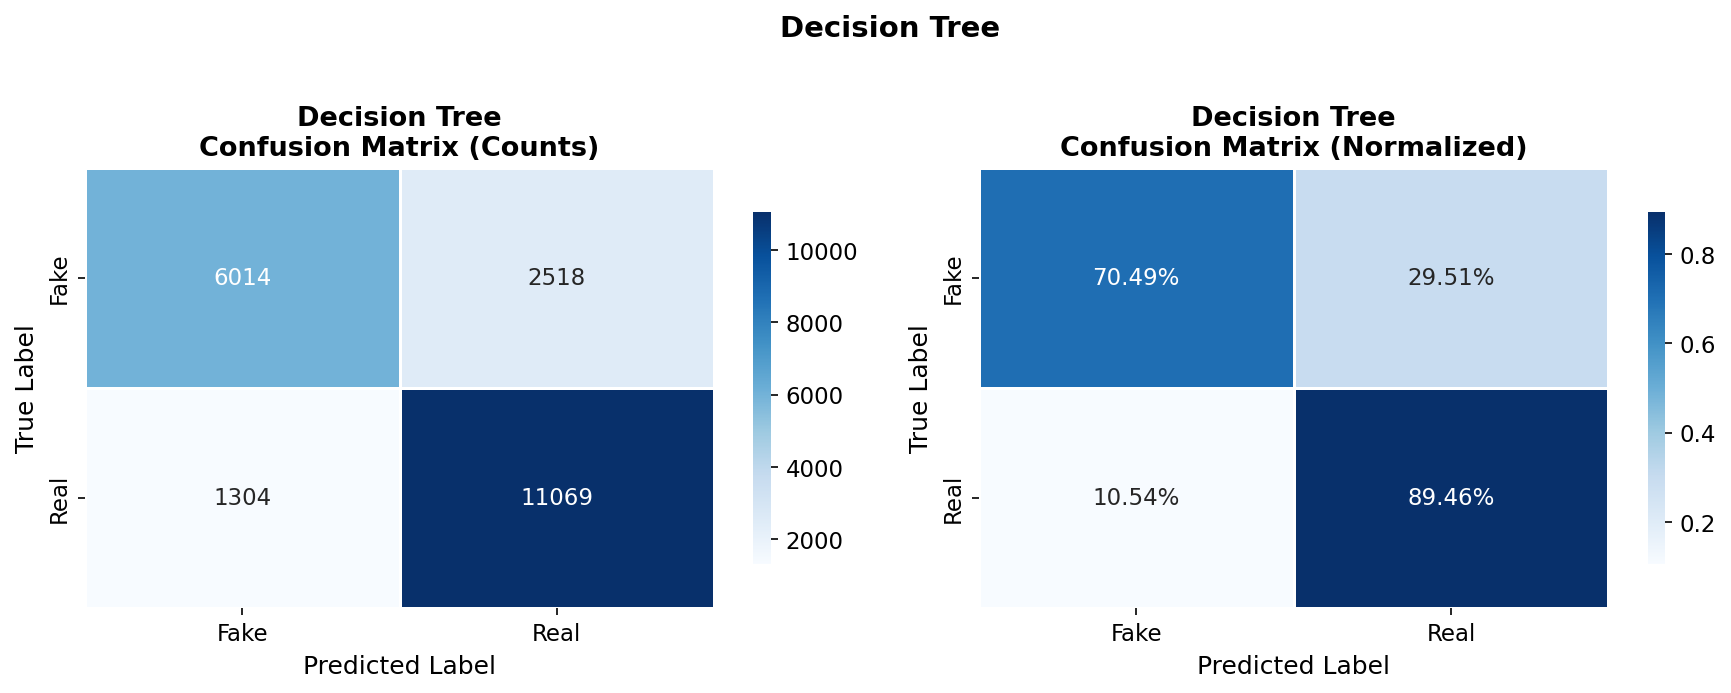

In [5]:
plot_confusion_matrix(y_test, y_pred, MODEL_NAME, FIGURES_DIR)

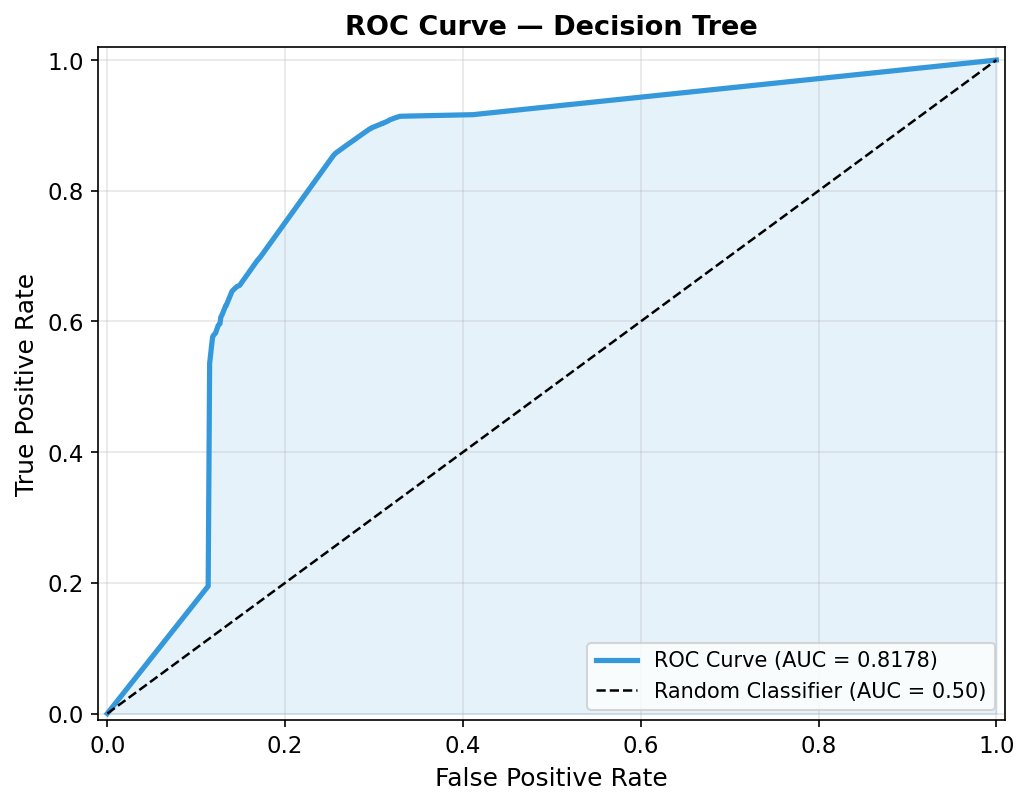

In [6]:
plot_roc_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

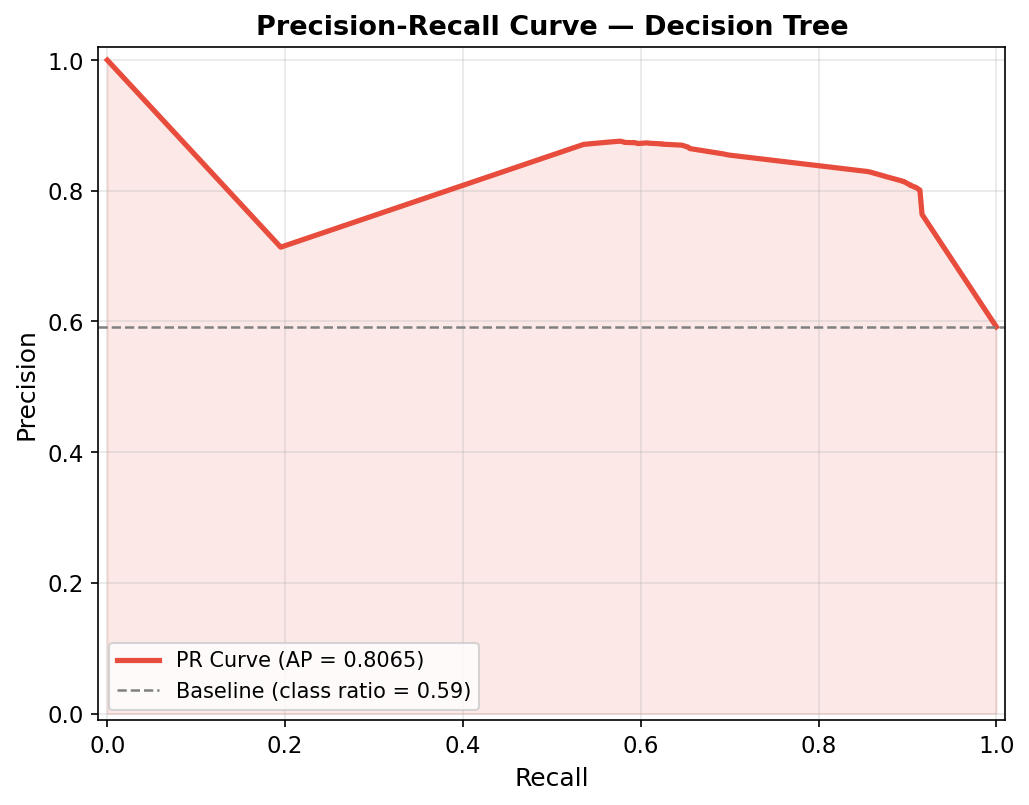

In [7]:
plot_pr_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

## Convergence: Accuracy vs Max Depth

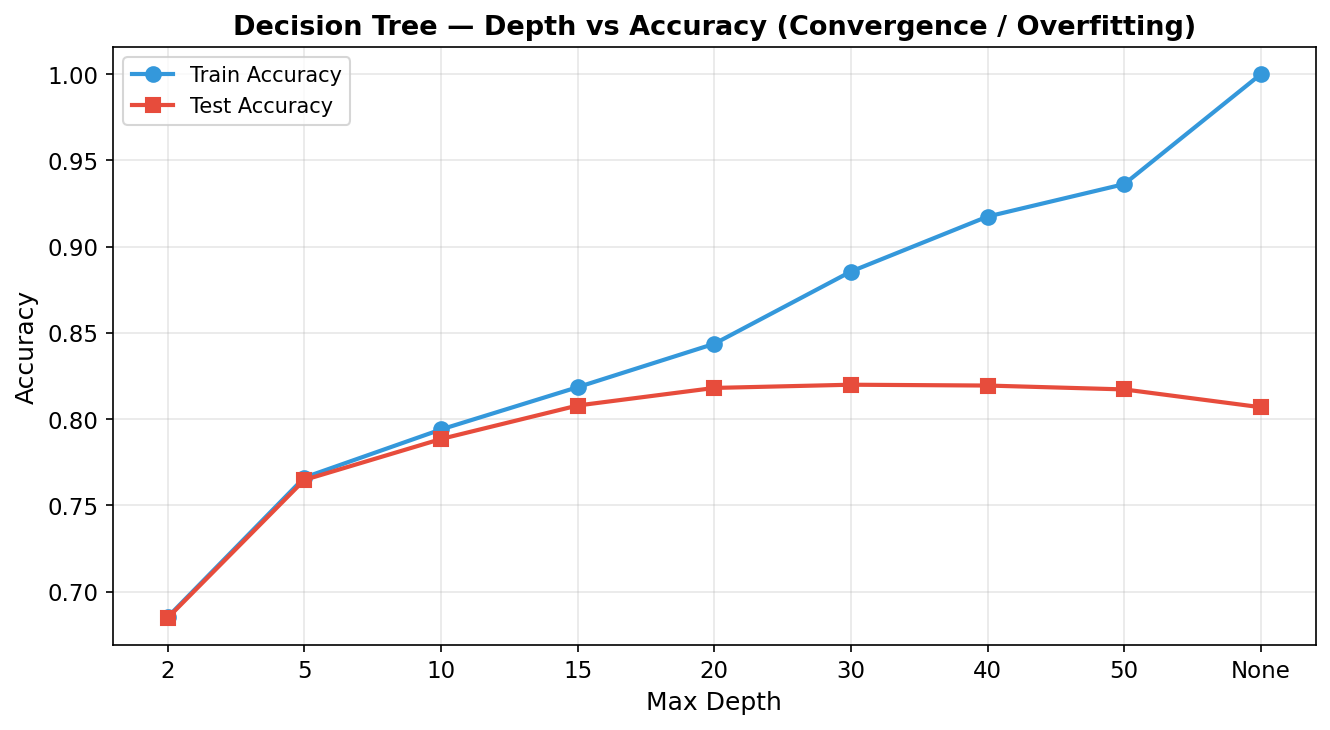

In [8]:
depths = [2, 5, 10, 15, 20, 30, 40, 50, None]
tr_accs, te_accs, depth_labels = [], [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42)
    m.fit(X_tr, y_train)
    tr_accs.append(accuracy_score(y_train, m.predict(X_tr)))
    te_accs.append(accuracy_score(y_test, m.predict(X_te)))
    depth_labels.append(str(d) if d else 'None')

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(len(depths)), tr_accs, 'o-', color='#3498db', lw=2, ms=7, label='Train Accuracy')
ax.plot(range(len(depths)), te_accs, 's-', color='#e74c3c', lw=2, ms=7, label='Test Accuracy')
ax.set_xticks(range(len(depths)))
ax.set_xticklabels(depth_labels)
ax.set_xlabel('Max Depth')
ax.set_ylabel('Accuracy')
ax.set_title('Decision Tree — Depth vs Accuracy (Convergence / Overfitting)')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'decision_tree_depth_curve.png'), dpi=150, bbox_inches='tight')
plt.show()

## Learning Curve

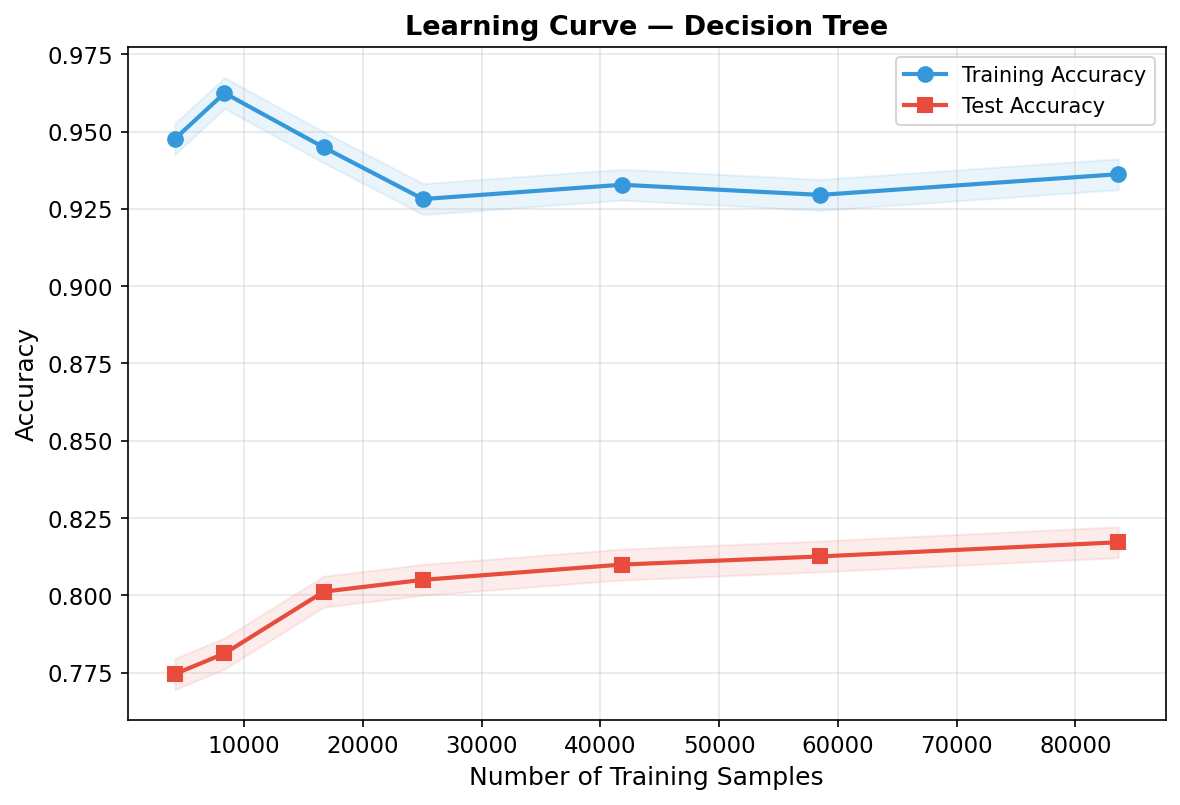

([4180, 8361, 16723, 25084, 41808, 58531, 83616],
 [0.9476076555023923,
  0.962444683650281,
  0.9448663517311487,
  0.9281613777706905,
  0.9327879831611174,
  0.9295074405016145,
  0.9361964217374665],
 [0.7745515426931356,
  0.7812006696962449,
  0.8011958861516384,
  0.8050227218368812,
  0.8099497727816312,
  0.8125807223152356,
  0.8171729251375269])

In [9]:
plot_learning_curve(model, X_tr, y_train, X_te, y_test, MODEL_NAME, FIGURES_DIR)

## Top Feature Importances

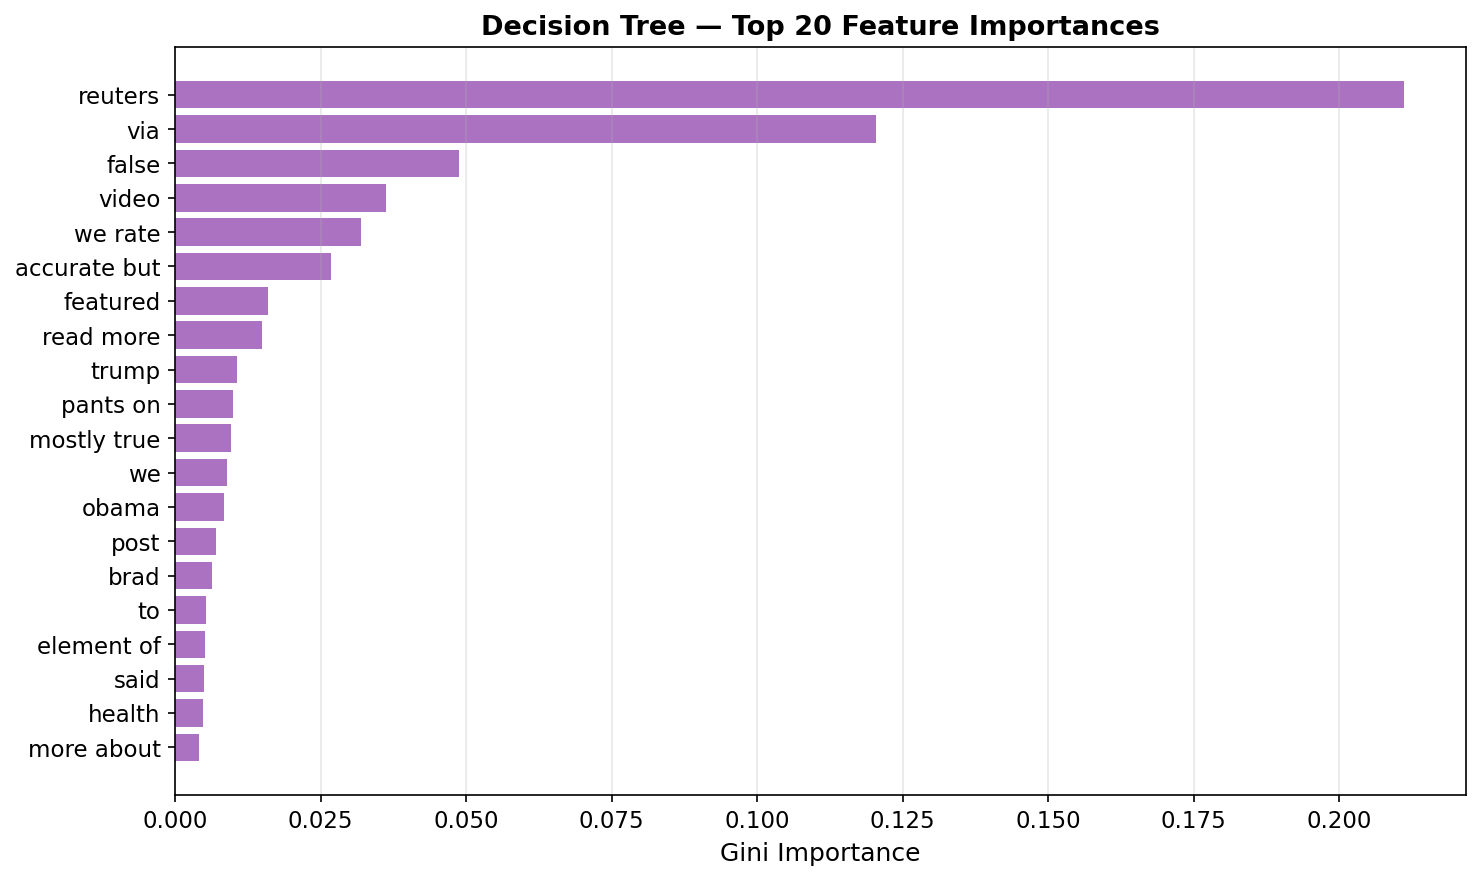

In [10]:
feat_names = np.array(tfidf.get_feature_names_out())
importances = model.feature_importances_
top_idx = np.argsort(importances)[-20:][::-1]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(feat_names[top_idx][::-1], importances[top_idx][::-1], color='#9b59b6', alpha=0.85)
ax.set_xlabel('Gini Importance')
ax.set_title('Decision Tree — Top 20 Feature Importances')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'decision_tree_feature_importance.png'), dpi=150, bbox_inches='tight')
plt.show()